# Pricing European Calls: Monte Carlo vs. Explicit Finite Differences

**Course:** Advanced Topics in Mathematical and Computational Finance  
**Author:** Jacob Lu  
**Date:** November 19, 2026

---

## Contents
1. Introduction
2. Setup
3. Task 1: Monte Carlo (Euler-Maruyama)
4. Task 2: Explicit Finite Difference Method
5. Order of Accuracy Study
6. Stability Study
7. Observations and Problems Encountered
8. Conclusion
9. References

## 1. Introduction

### 1.1 The financial problem

A European call option gives its holder the right, but not the obligation, to buy an underlying asset at a fixed strike price $E$ and expiry date $T$. If $S_T$ is the asset price at expiry, the holder receives the payoff

$$\max(S_T - E,\, 0).$$

We aim to find the theoretical fair price today, $V(S_0, t)$, given the spot price $S_0$, strike $E$, time to expiry $T-t$, volatility $\sigma$, risk-free rate $r$ and continuous dividend yield $D$.

The underlying is modelled as geometric Brownian motion. Under the risk-neutral measure, we have

$$dS = (r-D)\,S\,dt + \sigma S\,dW,$$

with the following two equivalent formulations.

**Probabilistic form (used in Task 1).** The price is the discounted expected payoff:

$$V(S,t) = e^{-r(T-t)}\,\mathbb{E}\big[\max(S_T-E,0)\big].$$

**PDE form (used in Task 2).** Delta hedging removes the risk, and $V$ satisfies the Black-Scholes equation

$$\frac{\partial V}{\partial t} + \tfrac12\sigma^2 S^2\frac{\partial^2 V}{\partial S^2}
+ (r-D)S\frac{\partial V}{\partial S} - rV = 0,\qquad S\in[0,\infty),\; t\in(0,T),$$

with the conditions

$$V(0,t)=0,\qquad \lim_{S\to\infty}V(S,t)\sim S,\qquad V(S,T)=\max(S-E,0).$$

The last condition is a terminal condition, since the solution is known at expiry and required today. Substituting $\tau = T-t$ turns this into a marching forward problem from $\tau=0$.

For constant coefficients, the Black-Scholes formula is a closed-form solution. We use it as the reference for every error reported in this notebook.

### 1.2 Numerical procedures

**Monte Carlo (Task 1).** We simulate $N$ paths of $S$ with the Euler-Maruyama scheme,

$$S_{n+1} = S_n + (r-D)S_n\delta t + \sigma S_n\sqrt{\delta t}\,Z_n,\qquad Z_n\sim\mathcal N(0,1),$$

then evaluate the payoff on each path, average, and discount. The error due to using $N$ realizations is $O(1/\sqrt{N})$, and the discretization error is $O(\delta t)$.

**Explicit finite difference method (Task 2).** We discretize the PDE on a grid in $(S,t)$ with $S_i = i\,\delta S$ and $t_k = T - k\,\delta t$ on a truncated domain $[0,S^*]$. We replace each derivative by a Taylor-series approximation, which gives an update of the form

$$V_i^{k+1} = \alpha_i V_{i-1}^k + \beta_i V_i^k + \gamma_i V_{i+1}^k.$$

Each new value depends only on known values from the previous time level, so the scheme is explicit and marches forward from the payoff. The error is $O(\delta t, \delta S^2)$, and its stability is conditional on $\delta t \le \frac{1}{\sigma^2 I^2}$, i.e. $\delta t = O(I^{-2})$, which is investigated in Section 6.

### 1.3 Aims and structure

We aim to:  
* (i) implement both methods and validate them against the closed form, 
* (ii) study how the option price responds to the input data, 
* (iii) measure the order of accuracy of the explicit scheme, 
* (iv) demonstrate what happens when the stability condition is violated, and 
* (v) compare the two methods in accuracy and cost.

We structure our report as follows: 
* Section 2 sets up the environment and benchmark, 
* Sections 3 and 4 cover Tasks 1 and 2, 
* Sections 5 and 6 cover the accuracy and stability studies, and 
* Sections 7 and 8 give observations and conclusions.

## 2. Setup

In [19]:
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm

# Record the environment so the report states what it was run on
print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"SciPy      {scipy.__version__}")
print(f"pandas     {pd.__version__}")
print(f"matplotlib {plt.matplotlib.__version__}")

Python     3.14.4
NumPy      2.4.6
SciPy      1.18.1
pandas     3.0.3
matplotlib 3.11.2


In [2]:
SEED = 42 # The answer to life, the universe, and everything
rng = np.random.default_rng(SEED)

# Plot and display defaults
plt.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### Base parameters

| Symbol | Meaning | Value |
|---|---|---|
| $S_0$ | spot price today | 100 |
| $E$ | strike | 100 |
| $T-t$ | time to expiry | 1 year |
| $\sigma$ | volatility | 0.20 |
| $r$ | risk-free rate | 0.05 |
| $D$ | dividend yield | 0.00 |

In [3]:
from dataclasses import dataclass, replace

@dataclass(frozen=True)
class Params:
    S0: float = 100.0     # spot
    E: float = 100.0      # strike
    T: float = 1.0        # time to expiry (T - t)
    sigma: float = 0.20   # volatility
    r: float = 0.05       # risk-free rate
    D: float = 0.0        # continuous dividend yield

base = Params()
base

Params(S0=100.0, E=100.0, T=1.0, sigma=0.2, r=0.05, D=0.0)

### Closed-form benchmark

The Black-Scholes formula serves as ground truth for both tasks. With $\tau = T-t$:
$$C = S e^{-D\tau}N(d_1) - E e^{-r\tau}N(d_2),\quad
d_1=\frac{\ln(S/E)+(r-D+\tfrac12\sigma^2)\tau}{\sigma\sqrt\tau},\quad d_2=d_1-\sigma\sqrt\tau$$

In [17]:
def bs_call(S, E, tau, sigma, r, D=0.0):
    # Closed-form Black-Scholes price of a European call (vectorised in S).
    S = np.asarray(S, dtype=float)
    if tau <= 0:
        return np.maximum(S - E, 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        d1 = (np.log(S / E) + (r - D + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    price = S * np.exp(-D * tau) * norm.cdf(d1) - E * np.exp(-r * tau) * norm.cdf(d2)
    return np.where(S == 0, 0.0, price)   # S = 0 gives log(0); the call is worth 0


def bs_call_p(p: Params):
    # Closed-form price at the spot S0 from a Params object
    return float(bs_call(p.S0, p.E, p.T, p.sigma, p.r, p.D))


exact = bs_call_p(base)
print(f"Black-Scholes price (base case): {exact:.6f}")   # expect ~10.4506
assert abs(exact - 10.4506) < 1e-3, "closed form does not match the known value"

Black-Scholes price (base case): 10.450584


### Helpers
Helper functions for timing and error reporting used throughout the notebook.

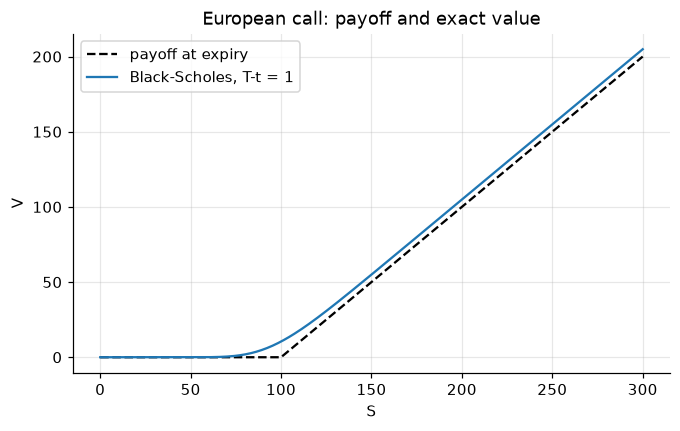

In [5]:
def timed(fn, *args, **kwargs):
    '''Run fn once and return (result, wall-clock seconds).'''
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    return out, time.perf_counter() - t0


def abs_err(approx, exact):
    return abs(approx - exact)


def rel_err(approx, exact):
    return abs(approx - exact) / abs(exact)


# Quick plot of the payoff and the exact price, handy as a visual sanity check
S_plot = np.linspace(0, 3 * base.E, 300)
plt.plot(S_plot, np.maximum(S_plot - base.E, 0), "k--", label="payoff at expiry")
plt.plot(S_plot, bs_call(S_plot, base.E, base.T, base.sigma, base.r, base.D), label="Black-Scholes, T-t = 1")
plt.xlabel("S"); plt.ylabel("V"); plt.title("European call: payoff and exact value"); plt.legend()
plt.show()

## 3. Task 1: Monte Carlo (Euler-Maruyama)
Recall the formula used to implement the Euler-Maruyama scheme: 
$$S_{n+1} = S_n + (r-D)S_n\,\Delta t + \sigma S_n\sqrt{\Delta t}\,Z_n,\qquad Z_n\sim\mathcal N(0,1)$$
### Implementation

In [11]:
def mc_euler_call(p, n_paths, n_steps, rng):
    dt = p.T / n_steps
    sqdt = np.sqrt(dt)
    S = np.full(n_paths, p.S0)
    for _ in range(n_steps):
        Z = rng.standard_normal(n_paths)
        S = S + (p.r - p.D) * S * dt + p.sigma * S * sqdt * Z
    disc_payoff = np.exp(-p.r * p.T) * np.maximum(S - p.E, 0.0)
    price = disc_payoff.mean()
    path_error = disc_payoff.std(ddof=1) / np.sqrt(n_paths)
    return price, path_error

### Test

In [ ]:
P, n_steps = 10**6, 100
price, se = mc_euler_call(base, P, n_steps, rng)
pd.DataFrame({
    "MC price": [price], "std error": [se],
    "95% CI low": [price - 1.96 * se], "95% CI high": [price + 1.96 * se],
    "exact": [exact], "error": [price - exact],
}, index=[f"P={P:.0e}, steps={n_steps}"])

,MC price,std error,95% CI low,95% CI high,exact,error
"P=1e+06, steps=100",10.460675,0.014701,10.431862,10.489488,10.450584,0.010091


## 4. Task 2: Explicit Finite Difference Method

The formulae used to implement the finite difference scheme are as follows: 

$$
\lambda = \delta t\, \sigma^2 I^2 < 1, \qquad K = \left\lceil \frac{T \sigma^2 I^2}{\lambda} \right\rceil
$$

$$
\begin{aligned}
S_i &= i\,\delta S, \qquad \delta S = \frac{S^*}{I}, \qquad S^* = I\,\delta S, \qquad i = 0,\dots,I \\[6pt]
t_k &= T - k\,\delta t, \qquad \delta t = \frac{T}{K}, \qquad k = 0,\dots,K
\end{aligned}
$$

$$
\begin{aligned}
V_i^0 &= \max(S_i - E,\, 0) && i = 0,\dots,I \\[6pt]
V_0^{k+1} &= (1 - r\,\delta t)\, V_0^k && i = 0 \\[6pt]
V_i^{k+1} &= \alpha_i V_{i-1}^k + \beta_i V_i^k + \gamma_i V_{i+1}^k && i = 1,\dots,I-1 \\[6pt]
V_I^{k+1} &= (\alpha_I - \gamma_I)\, V_{I-1}^k + (\beta_I + 2\gamma_I)\, V_I^k && i = I, \quad V_{I+1}^k = 2V_I^k - V_{I-1}^k
\end{aligned}
$$

$$
\begin{aligned}
\alpha_i &= \tfrac12 \sigma^2 i^2 \,\delta t - \tfrac12 (r-D)\, i\, \delta t \\[4pt]
\beta_i  &= 1 - (\sigma^2 i^2 + r)\, \delta t \\[4pt]
\gamma_i &= \tfrac12 \sigma^2 i^2 \,\delta t + \tfrac12 (r-D)\, i\, \delta t
\end{aligned}
$$

### Implementation

In [32]:
def stability_ratio(p, I, K):
    # lambda = dt * sigma^2 * I^2; according to von Neumann, this should be less than 1 for stability.
    return (p.T / K) * p.sigma**2 * I**2

def min_steps(p, I, lam=0.9):
    # Smallest K giving stability ratio <= lam (again lam < 1 is required for stability).
    return int(np.ceil(p.T * p.sigma**2 * I**2 / lam))

def explicit_fdm_call(p, S_star, I, K):
    dS, dt = S_star / I, p.T / K                  # delta S, delta t
    if stability_ratio(p, I, K) > 1:
        warnings.warn("von Neumann bound violated")

    i = np.arange(I + 1)                          # S counter, i = 0,...,I
    S = i * dS
    V = np.maximum(S - p.E, 0.0)                  # V_i^0 = payoff

    ii = i[1:-1]                                  # interior nodes, i = 1,...,I-1
    alpha = 0.5 * p.sigma**2 * ii**2 * dt - 0.5 * (p.r - p.D) * ii * dt
    beta = 1.0 - (p.sigma**2 * ii**2 + p.r) * dt
    gamma = 0.5 * p.sigma**2 * ii**2 * dt + 0.5 * (p.r - p.D) * ii * dt

    # same coefficients at i = I, for the upper boundary
    alpha_I = 0.5 * p.sigma**2 * I**2 * dt - 0.5 * (p.r - p.D) * I * dt
    beta_I = 1.0 - (p.sigma**2 * I**2 + p.r) * dt
    gamma_I = 0.5 * p.sigma**2 * I**2 * dt + 0.5 * (p.r - p.D) * I * dt

    for k in range(K):                            # time counter: V^k -> V^{k+1}
        Vn = np.empty_like(V)
        Vn[1:-1] = alpha * V[:-2] + beta * V[1:-1] + gamma * V[2:]
        Vn[0] = (1.0 - p.r * dt) * V[0]
        Vn[-1] = (alpha_I - gamma_I) * V[-2] + (beta_I + 2.0 * gamma_I) * V[-1]
        V = Vn
    return S, V


def fdm_price(p, S_star, I, K):
    # FDM price at S0 (interpolated; exact node value when S0 sits on the grid).
    S, V = explicit_fdm_call(p, S_star, I, K)
    return float(np.interp(p.S0, S, V))

### Test

I = 300, K = 4001, dS = 1.0000, dt = 0.000250, lambda = 0.900
FDM price at S0 = 10.448375   exact = 10.450584   error = -2.21e-03


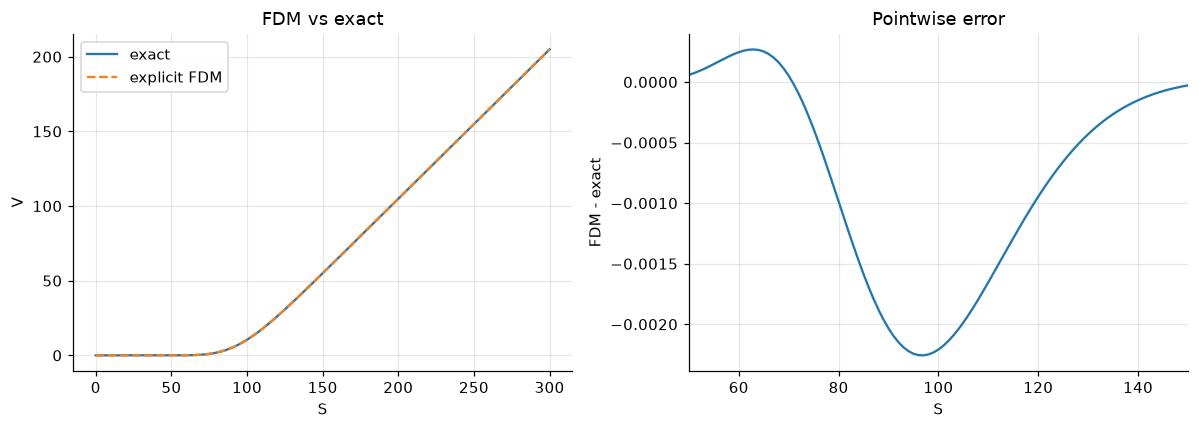

In [15]:
S_star, I = 3 * base.E, 300
K = min_steps(base, I, lam=0.9)
S_grid, V_fdm = explicit_fdm_call(base, S_star, I, K)
V_exact = bs_call(S_grid, base.E, base.T, base.sigma, base.r, base.D)
price_fdm = np.interp(base.S0, S_grid, V_fdm)

print(f"I = {I}, K = {K}, dS = {S_star/I:.4f}, dt = {base.T/K:.6f}, lambda = {stability_ratio(base, I, K):.3f}")
print(f"FDM price at S0 = {price_fdm:.6f}   exact = {exact:.6f}   error = {price_fdm - exact:+.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(S_grid, V_exact, label="exact"); ax[0].plot(S_grid, V_fdm, "--", label="explicit FDM")
ax[0].set(xlabel="S", ylabel="V", title="FDM vs exact"); ax[0].legend()
ax[1].plot(S_grid, V_fdm - V_exact)
ax[1].set(xlabel="S", ylabel="FDM - exact", title="Pointwise error", xlim=(0.5 * base.E, 1.5 * base.E))
plt.tight_layout(); plt.show()

## 5. Order of Accuracy Study
### Monte Carlo
The Monte Carlo price has two error sources. The sampling error shrinks like $1/\sqrt{N}$ in the number of paths $N$, and the Euler-Maruyama scheme adds a bias that shrinks with the time step $\delta t$. We test the two separately, varying $N$ by a factor of $10$ and $\delta t$ by a factor of $2$.

| Study | Varied | Fixed | Expected order |
|---|---|---|---|
| A: joint refinement | $N = 10^3, 10^4, 10^5, 10^6$ | $\delta t \propto N^{-1/2}$ (steps $=\lceil 0.05\sqrt{N}\,\rceil$), 10 repeated runs per $N$ | $-\tfrac12$ in $N$ |
| B: paths only | $N = 10^3, 10^4, 10^5, 10^6$ | 100 Euler steps, 10 repeated runs per $N$ | $-\tfrac12$ in $N$ |
| C: time steps only | 1, 2, 4, 8, 16 steps | $N = 10^6$ with the same random numbers at every level | $1$ in $\delta t$ |

- **A** lets $\delta t$ shrink as $N^{-1/2}$, so the bias and the sampling error fall at the same rate and neither dominates as $N$ grows.
- **B** isolates the sampling error by making $\delta t$ small enough that the bias is negligible. Each run is repeated 10 times, so the error is an RMS over repeated runs. A single run gives only one sample of the error, which scatters around the sampling error.
- **C** reuses the same Brownian increments at every step count. The sampling error is then identical across levels and cancels when each level is compared with the finest one (32 steps).

In [24]:
# A: joint refinement, delta t proportional to N^(-1/2)
rng = np.random.default_rng(SEED)
rows = []
for N in [10**3, 10**4, 10**5, 10**6]:
    steps = max(1, int(np.ceil(0.05 * np.sqrt(N))))
    res = np.array([mc_euler_call(base, N, steps, rng) for _ in range(10)])
    rows.append({"N": f"1e{int(np.log10(N))}", "steps": steps,
                 "mean sampling error": res[:, 1].mean(),
                 "RMS error": np.sqrt(np.mean((res[:, 0] - exact) ** 2))})
A = pd.DataFrame(rows)
display(A.style.hide(axis="index").format({"mean sampling error": "{:.4f}", "RMS error": "{:.4f}"}))

# B: paths only, delta t fixed small
rng = np.random.default_rng(SEED)
rows = []
for N in [10**3, 10**4, 10**5, 10**6]:
    res = np.array([mc_euler_call(base, N, 100, rng) for _ in range(10)])
    rows.append({"N": f"1e{int(np.log10(N))}", "steps": 100,
                 "mean sampling error": res[:, 1].mean(),
                 "RMS error": np.sqrt(np.mean((res[:, 0] - exact) ** 2))})
B = pd.DataFrame(rows)
display(B.style.hide(axis="index").format({"mean sampling error": "{:.4f}", "RMS error": "{:.4f}"}))

# C: time steps only, coupled Brownian increments
N, nf = 10**6, 32
Z = np.random.default_rng(SEED).standard_normal((nf, N))
prices = {}
for n in [1, 2, 4, 8, 16, 32]:
    dt = base.T / n
    dW = Z.reshape(n, nf // n, N).sum(axis=1) / np.sqrt(nf // n)
    S = np.full(N, base.S0)
    for j in range(n):
        S = S + (base.r - base.D) * S * dt + base.sigma * S * np.sqrt(dt) * dW[j]
    prices[n] = np.exp(-base.r * base.T) * np.maximum(S - base.E, 0).mean()
C = pd.DataFrame({"steps": list(prices), "price": list(prices.values())})
C["dt"] = base.T / C["steps"]
C["diff vs 32 steps"] = C["price"] - prices[32]
e = C["diff vs 32 steps"].abs().iloc[:-1].values
C["rate"] = np.r_[np.nan, np.log2(e[:-1] / e[1:]), np.nan]
display(C)

N,steps,mean sampling error,RMS error
1e3,2,0.4380,0.6913
1e4,5,0.1423,0.1159
1e5,16,0.0461,0.0581
1e6,50,0.0147,0.0169


N,steps,mean sampling error,RMS error
1e3,100,0.4644,0.3495
1e4,100,0.1473,0.1334
1e5,100,0.0466,0.0482
1e6,100,0.0147,0.0129


,steps,price,dt,diff vs 32 steps,rate
0,1,10.210004,1.00000,-0.245723,NaN
1,2,10.366404,0.50000,-0.089323,1.459922
2,4,10.421772,0.25000,-0.033955,1.395430
3,8,10.442396,0.12500,-0.013331,1.348837
4,16,10.452010,0.06250,-0.003717,1.842617
5,32,10.455727,0.03125,0.000000,NaN


### Finite Difference Method
The scheme is first order in time and second order in asset price (space), so the error should behave like $O(\delta t, \delta S^2)$. We test this by halving the step sizes repeatedly and checking how fast the error shrinks.

Three studies isolate the different error sources:

| Study | Varied | Fixed | Expected order |
|---|---|---|---|
| A: joint refinement | $I = 30, 60, 120, 240, 480$ | $K$ set so $\lambda = \delta t\,\sigma^2 I^2 = 0.9$ | 2 in $\delta S$ |
| B: space only | $I = 30, 60, 120, 240, 480$ | $K = 20000$ ($\delta t = 5\times10^{-5}$) | 2 in $\delta S$ |
| C: time only | $K = 4000, 8000, 16000, 32000$ | $I = 300$ | 1 in $\delta t$ |

- **A** fixes $\lambda < 1$ by ensuring $\delta t \propto \delta S^2$, so both error terms shrink together and the overall rate is expected to be 2 in $\delta S$.
- **B** isolates the spatial error by making $\delta t$ small enough that the time error is negligible. The fixed $\delta t$ lies inside the stability bound for every $I$ used.
- **C** isolates the time error by fixing a grid with small $\delta S$. The exact price contains the spatial error, which would swamp the time error, so errors are measured against a reference run on the same grid with $K = 128000$.

In all runs $S^* = 3E$, so the truncation error does not change between refinements. Each $I$ is a multiple of 3, so $E$ and $S_0$ sit on grid nodes.

,I,K,dS,dt,error,rate
0,30,41,10.000,0.024390,-0.232014,NaN
1,60,161,5.000,0.006211,-0.055812,2.055574
2,120,641,2.500,0.001560,-0.013836,2.012137
3,240,2561,1.250,0.000390,-0.003452,2.002955
4,480,10241,0.625,0.000098,-0.000863,2.000734


,I,K,dS,dt,error,rate
0,30,20000,10.000,0.00005,-0.260722,NaN
1,60,20000,5.000,0.00005,-0.062431,2.062171
2,120,20000,2.500,0.00005,-0.015429,2.016579
3,240,20000,1.250,0.00005,-0.003810,2.017957
4,480,20000,0.625,0.00005,-0.000913,2.061685


,I,K,dt,error,rate
0,300,4000,0.000250,0.000254,NaN
1,300,8000,0.000125,0.000123,1.047316
2,300,16000,0.000063,0.000057,1.099541
3,300,32000,0.000031,0.000025,1.222395


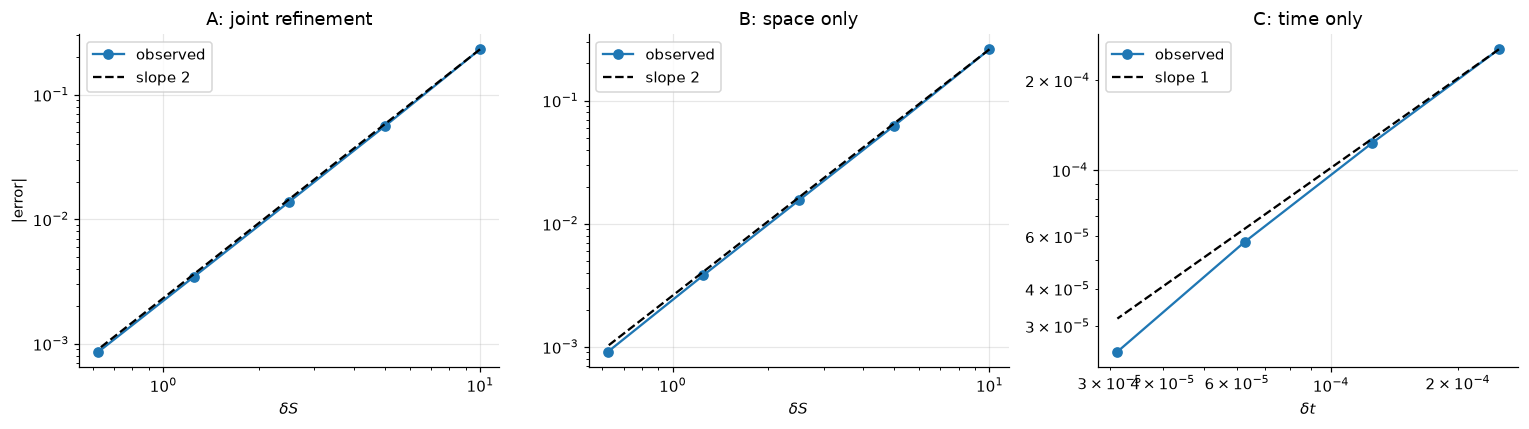

In [18]:
def rates(err):
    err = np.asarray(err)
    return np.r_[np.nan, np.log2(err[:-1] / err[1:])]

S_star = 3 * base.E
Is = [30, 60, 120, 240, 480]

# A: joint refinement, lambda = 0.9
rows = []
for I in Is:
    K = min_steps(base, I, 0.9)
    rows.append({"I": I, "K": K, "dS": S_star / I, "dt": base.T / K,
                 "error": fdm_price(base, S_star, I, K) - exact})
A = pd.DataFrame(rows); A["rate"] = rates(A["error"].abs())

# B: space only, fixed small dt
rows = []
for I in Is:
    rows.append({"I": I, "K": 20000, "dS": S_star / I, "dt": base.T / 20000,
                 "error": fdm_price(base, S_star, I, 20000) - exact})
B = pd.DataFrame(rows); B["rate"] = rates(B["error"].abs())

# C: time only, fixed I, error against a fine-dt reference on the same grid
I = 300
ref = fdm_price(base, S_star, I, 128000)
rows = []
for K in [4000, 8000, 16000, 32000]:
    rows.append({"I": I, "K": K, "dt": base.T / K,
                 "error": fdm_price(base, S_star, I, K) - ref})
C = pd.DataFrame(rows); C["rate"] = rates(C["error"].abs())

display(A, B, C)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].loglog(A["dS"], A["error"].abs(), "o-", label="observed")
ax[0].loglog(A["dS"], A["error"].abs().iloc[0] * (A["dS"] / A["dS"].iloc[0])**2, "k--", label="slope 2")
ax[0].set(xlabel=r"$\delta S$", ylabel="|error|", title="A: joint refinement"); ax[0].legend()
ax[1].loglog(B["dS"], B["error"].abs(), "o-", label="observed")
ax[1].loglog(B["dS"], B["error"].abs().iloc[0] * (B["dS"] / B["dS"].iloc[0])**2, "k--", label="slope 2")
ax[1].set(xlabel=r"$\delta S$", title="B: space only"); ax[1].legend()
ax[2].loglog(C["dt"], C["error"].abs(), "o-", label="observed")
ax[2].loglog(C["dt"], C["error"].abs().iloc[0] * (C["dt"] / C["dt"].iloc[0]), "k--", label="slope 1")
ax[2].set(xlabel=r"$\delta t$", title="C: time only"); ax[2].legend()
plt.tight_layout(); plt.show()

### Results

**Monte Carlo.** With the time step held small and fixed (study B), the sampling error falls by a factor of about $\sqrt{10}$ for every tenfold increase in $N$ (0.464, 0.147, 0.047, 0.0147), which is the expected $N^{-1/2}$ behaviour; the RMS error over repeated runs follows the same trend, though with only 10 repeats it is noisy. With $N$ fixed and the time step varied (study C), the Euler bias falls with $\delta t$ at a rate of 1.46, 1.40 and 1.35 for the first three refinements, somewhat above first order, which is expected while the step sizes are still too coarse for the asymptotic first-order behaviour to apply; the final rate (1.84) is unreliable since it is measured against a 32-step reference that has a bias of its own. Choosing $\delta t \propto N^{-1/2}$ so that the two errors fall together (study A) changed nothing: the sampling errors match those in B (0.438, 0.142, 0.046, 0.0147), since the Euler bias is already small next to the sampling error at every $N$ used, so the benefit of the rule would be in the number of time steps needed, and would show up in the error only for much larger $N$ or a larger bias.

**Explicit FDM.** The observed orders match the theory. With $\lambda$ held at 0.9 (study A), the error at $S_0$ falls by a factor of 4 each time $\delta S$ is halved, with rates of 2.06, 2.01, 2.00 and 2.00, so the scheme is second order in $\delta S$ when $\delta t$ is tied to $\delta S^2$ by the stability condition. Study B, with $\delta t$ fixed small, gives rates between 2.02 and 2.06, which confirms the spatial order on its own. Study C, with the grid fixed, gives rates of 1.05 and 1.10 at the first two refinements, consistent with first order in $\delta t$. The third rate (1.22) is inflated because the reference run has a small time error of its own, so it should not be read as a departure from first order. The errors are negative throughout, so the scheme slightly underestimates the price.

**Comparison.** At the finest settings used, FDM reaches an error of about $10^{-3}$ ($I = 480$), while Monte Carlo with $10^6$ paths has a sampling error of about $10^{-2}$. FDM's error also falls at a known rate in its step sizes, whereas Monte Carlo's falls only like $N^{-1/2}$, so each extra digit of accuracy needs 100 times more paths. The price of FDM's accuracy is the stability condition $\delta t \le 1/(\sigma^2 I^2)$, which ties the time step to the asset step, while Monte Carlo has no such restriction.

## 6. Stability Study

A von Neumann analysis shows that the explicit scheme is stable only if

$$\lambda := \delta t\,\sigma^2 I^2 < 1 \implies \delta t \sim O(I^{-2}).$$

We test this condition empirically by fixing the grid ($I = 150$, $S^* = 3E$) and varying $K$ so that $\lambda$ takes the values $0.9$, $1.1$, $1.15$ and $1.2$. For each run we record the error at $S_0$, the maximum of $|V|$ over the grid at every time step, and the solution at expiry compared with the exact curve.

lambda,K,error at S0,max |V| at end
0.898,1002,-8.85e-03,2.05e+02
1.098,820,-8.61e-03,2.05e+02
1.148,784,-8.56e-03,4.28e+21
1.198,751,-8.50e-03,3.44e+46


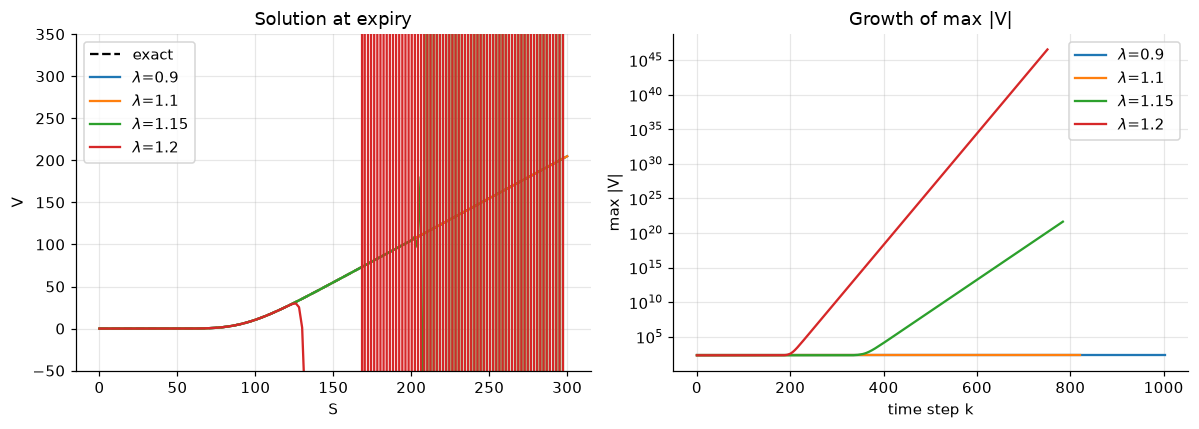

In [31]:
def fdm_track(p, S_star, I, K):
    """Same explicit scheme as explicit_fdm_call, also returning max|V| at every time step."""
    dS, dt = S_star / I, p.T / K
    i = np.arange(I + 1)
    S = i * dS
    V = np.maximum(S - p.E, 0.0)
    ii = i[1:-1]
    alpha = 0.5 * p.sigma**2 * ii**2 * dt - 0.5 * (p.r - p.D) * ii * dt
    beta = 1.0 - (p.sigma**2 * ii**2 + p.r) * dt
    gamma = 0.5 * p.sigma**2 * ii**2 * dt + 0.5 * (p.r - p.D) * ii * dt
    alpha_I = 0.5 * p.sigma**2 * I**2 * dt - 0.5 * (p.r - p.D) * I * dt
    beta_I = 1.0 - (p.sigma**2 * I**2 + p.r) * dt
    gamma_I = 0.5 * p.sigma**2 * I**2 * dt + 0.5 * (p.r - p.D) * I * dt
    vmax = [np.abs(V).max()]
    for k in range(K):
        Vn = np.empty_like(V)
        Vn[1:-1] = alpha * V[:-2] + beta * V[1:-1] + gamma * V[2:]
        Vn[0] = (1.0 - p.r * dt) * V[0]
        Vn[-1] = (alpha_I - gamma_I) * V[-2] + (beta_I + 2.0 * gamma_I) * V[-1]
        V = Vn
        vmax.append(np.abs(V).max())
    return S, V, np.array(vmax)


I, S_star = 150, 3 * base.E                 # I is a multiple of 3
K_bound = min_steps(base, I, lam=1.0)       # smallest K allowed by the bound
lams = [0.9, 1.1, 1.15, 1.2]

results, rows = {}, []
with np.errstate(all="ignore"):
    for lam in lams:
        K = int(np.ceil(K_bound / lam))
        S, V, vmax = fdm_track(base, S_star, I, K)
        results[lam] = (S, V, vmax)
        rows.append({"lambda": stability_ratio(base, I, K), "K": K,
                     "error at S0": np.interp(base.S0, S, V) - exact,
                     "max |V| at end": vmax[-1]})
display(pd.DataFrame(rows).style.hide(axis="index").format(
    {"lambda": "{:.3f}", "error at S0": "{:.2e}", "max |V| at end": "{:.2e}"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
V_exact = bs_call(results[0.9][0], base.E, base.T, base.sigma, base.r, base.D)
ax[0].plot(results[0.9][0], V_exact, "k--", label="exact")
for lam in lams:
    ax[0].plot(*results[lam][:2], label=f"$\\lambda$={lam}")
ax[0].set(xlabel="S", ylabel="V", title="Solution at expiry", ylim=(-50, 350)); ax[0].legend()
for lam in lams:
    ax[1].semilogy(results[lam][2], label=f"$\\lambda$={lam}")
ax[1].set(xlabel="time step k", ylabel="max |V|", title="Growth of max |V|"); ax[1].legend()
plt.tight_layout(); plt.show()

### Results

The stability condition $\lambda < 1$ is confirmed as a safe bound. At $\lambda = 0.9$ the scheme is stable, and at $\lambda = 1.1$ it still holds within the run length, so the bound is conservative in practice. Instability becomes noticeable from $\lambda = 1.15$, where $\max|V|$ grows exponentially, and it is faster at $\lambda = 1.2$. In practice, $\delta t$ should be chosen with $\lambda$ comfortably below 1.

## 7. Observations and Problems Encountered

The main problem we ran into was that the Monte Carlo study was slow. The full version (20 repeated runs per $N$ up to $10^6$ paths, 200 Euler steps in study B, and $2\times10^6$ coupled paths over 64 time levels in study C) took too long to run, so we cut it to 10 repeated runs, 100 steps in study B, and $N = 10^6$ with 32 time levels in study C. This costs some statistical precision: the RMS error over 10 repeats is only accurate to about $1/\sqrt{2n} = 1/\sqrt{20} \approx 22\%$, so small differences between it and the sampling error are noise, and study C has one fewer level. Regardless, the sampling error itself is still empirically $O(N^{-1/2})$, so the conclusions do not change.

A related limitation is that measuring the order for one error source means comparing with a finer reference run, and that reference has a small error of its own. This inflates the rates at the finest levels, which is why the FDM time rates drift above 1 (1.05, 1.10, 1.22) and the final Monte Carlo rate (1.84) is unreliable, so only the first rate in each series is a clean estimate.

In the stability experiment, the bound $\lambda < 1$ turned out to be a guarantee and not the exact point of failure: the scheme survived to $\lambda = 1.1$ and only failed at $\lambda = 1.15$. It was also not obvious from the error at $S_0$, which was nearly identical in all four runs because the oscillations stayed at large $S$, so the maximum of $|V|$ is the better indicator of instability.

## 8. Conclusion

We priced a European call with two methods, Monte Carlo with the Euler-Maruyama scheme and the explicit finite difference method, and both reproduce the Black-Scholes price. The explicit scheme converged at the orders predicted by the theory, second order in $\delta S$ and first order in $\delta t$, and it was stable for $\lambda = \delta t\,\sigma^2 I^2 < 1$. The bound proved conservative in practice, since the scheme only failed visibly at $\lambda = 1.15$, but beyond it the errors grew exponentially. The Monte Carlo sampling error largely overshadowed the discretization error at every setting, so tying $\delta t$ to $N$ made no visible difference to the accuracy.

At the settings tested, the finite difference method was the more accurate of the two, reaching errors around $10^{-3}$ against a Monte Carlo sampling error of about $10^{-2}$ at $10^6$ paths, but it comes with the stability restriction $\delta t = O(I^{-2})$. Monte Carlo has no such restriction, but each extra digit of accuracy needs a hundred times more paths. For a single vanilla option in few dimensions, the finite difference method is the natural choice, while Monte Carlo becomes preferable when the problem has many dimensions or no convenient PDE formulation.

## 9. References

1. Wilmott, P. *Paul Wilmott on Quantitative Finance* / *Paul Wilmott Introduces Quantitative Finance*. Wiley.
2. Course lecture notes, *Mathematical and Computational Finance*.